> Run from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/geoai-hybrid-ga-pso-anfis-wind-forecasting). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: GA → PSO → ANFIS / CNN-LSTM quantile forecasting
Simplified, CPU-fast version of `src/train_eval.py` (tiny GA/PSO budgets). Reimplementation; numbers will differ from the paper.

In [1]:
import os, sys, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
# repo root = folder containing src/ (works from notebooks/ or repo root, Windows/Linux/Colab)
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src').is_dir()), Path.cwd())
sys.path.insert(0, str(ROOT))
REPO = 'geoai-hybrid-ga-pso-anfis-wind-forecasting'

def find_csv(name):
    """../data -> data -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / name, Path.cwd() / 'data' / name, ROOT / 'data' / name]:
        if p.exists(): return p
    out = ROOT / 'data' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        from src.sites import synthetic_sites; synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        from src.data import synthetic_scada; d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
print('repo root:', ROOT)

repo root: geoai-hybrid-ga-pso-anfis-wind-forecasting


## 1. Load the committed synthetic multi-site CSV
`data/synthetic_sites.csv` is **synthetic** (seeded `scripts/make_synthetic.py`), not the reanalysis data used in the paper.

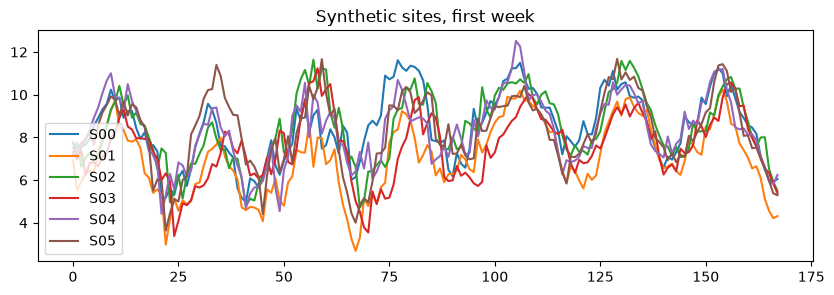

In [2]:
import pandas as pd
from src.sites import load_sites_csv, to_tensor, windows
from src.metrics import regression_metrics
df = load_sites_csv(find_csv('synthetic_sites.csv')); W, static, names = to_tensor(df)
pd.DataFrame(W[:24*7], columns=names).plot(figsize=(10,3), title='Synthetic sites, first week'); plt.show()

## 2. Windows over all sites → target site at horizons 1 h and 6 h

In [3]:
hz=[1,6]; T=len(W); a1,a2=int(T*.7),int(T*.85); mu,sd=W[:a1].mean(),W[:a1].std(); Wn=(W-mu)/sd; st=(static-static.mean(0))/(static.std(0)+1e-6)
def part(lo,hi):
    X,Y,i=windows(Wn[lo:hi],24,hz); return torch.tensor(X),torch.tensor(st[i]),torch.tensor(Y)
tr,va,te=part(0,a1),part(a1-24,a2),part(a2-24,T)

## 3. Layer 1 GA (architecture genes) and Layer 2 PSO (learning rate, dropout) — tiny budgets

In [4]:
from src.train_eval import train, mc_predict, crps_from_quantiles
from src.optimise import ga, pso
best,_ = ga(lambda c: train(c,(tr,va),1)[1], pop=3, gens=1)
gb,_ = pso(lambda p: train({**best,'lr':10**p[0],'dropout':p[1]},(tr,va),1)[1], [(-3.5,-2.0),(0.0,0.3)], particles=2, iters=1)
cfg = {**best,'lr':float(10**gb[0]),'dropout':float(gb[1])}; cfg

GA gen 0: best val loss 0.2228 {'filters': 64, 'hidden': 32, 'n_rules': 8}


PSO iter 0: best val loss 0.1917 at [-2.3445, 0.00527]


{'filters': 64,
 'hidden': 32,
 'n_rules': 8,
 'lr': 0.004523745601612876,
 'dropout': 0.005270388171536292}

## 4. Train the ANFIS → CNN-LSTM quantile model, MC-dropout predict, evaluate

In [5]:
m,_ = train(cfg,(tr,va),2); q = mc_predict(m, te[0], te[1], n=10)*sd+mu; y = te[2].numpy()*sd+mu
for j,h in enumerate(hz): print(f'{h}h', regression_metrics(y[:,j], q[:,j,2]), 'CRPS=%.3f' % crps_from_quantiles(q[:,j], y[:,j]))

1h {'MAE': 0.5494114915718211, 'RMSE': 0.7447264088681006, 'MAPE_%': 5.955972989733993, 'R2': 0.7972784767541476} CRPS=0.376
6h {'MAE': 1.3759660185984148, 'RMSE': 1.7187105110847474, 'MAPE_%': 14.471899249939678, 'R2': -0.08448022028794422} CRPS=0.877


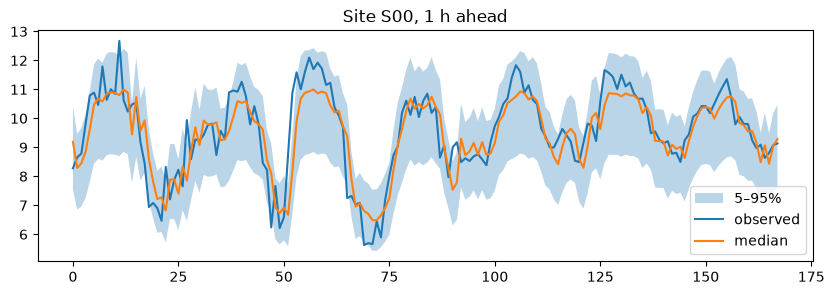

In [6]:
s=slice(0,168*len(names),len(names)); plt.figure(figsize=(10,3)); plt.fill_between(range(168), q[s,0,0], q[s,0,-1], alpha=.3, label='5–95%'); plt.plot(y[s,0], label='observed'); plt.plot(q[s,0,2], label='median'); plt.legend(); plt.title('Site S00, 1 h ahead'); plt.show()